# θ_t and Θ_reg near the end of the transport, with and without the terminal-phase steps
**Question.** Θ_reg(1), the smoothed coefficients used for log p, comes out very different depending on whether the last 318 steps of the run (the terminal phase, or tail) are included in its fit. Where does the difference appear, and how much does each estimate vary between seeds?
**Method.** Run J8 cut (M = 1024, J = 8, Q=3 channels with periods > 32 samples not imposed), 3 seeds, λ = 1e-4, no L_6 pin. Θ_reg solved twice on the same saved system: **A** with the tail steps, **B** without them. Compared with θ_t, the coefficients computed at each step of the run.
**Result.** With the tail in the fit (A), Θ_reg oscillates strongly over the whole end of the run (1 − t from 1e-2 to 1e-4, seed 0) and ends far from θ_t; without it (B), Θ_reg follows the mean of θ_t smoothly. B is also the most reproducible across seeds (median std 20 nats per coefficient, against 59 for A and 1158 for θ_t at the last step). Single λ = 1e-4, one configuration.

Units: each coefficient θ_i is shown as θ_i · sd(φ_i), in nats: the change of log p when statistic φ_i moves by one standard deviation (sd over the final samples of seed 0). This puts all statistics on one scale.

In [1]:
import viz_theta_tail as vt
%matplotlib inline
d = vt.load('theta_tail_m1024/theta_tail_J8cut_lam1e-4.npz')   # relative to terminal_phase_test/

## 1. The time steps
h_k = t_{k+1} − t_k. The run takes 27 500 planned steps, then the tail: a few hundred steps 3–5 decades shorter, until every imposed statistic matches the data. In time the whole tail is tiny; in number of steps it is not.

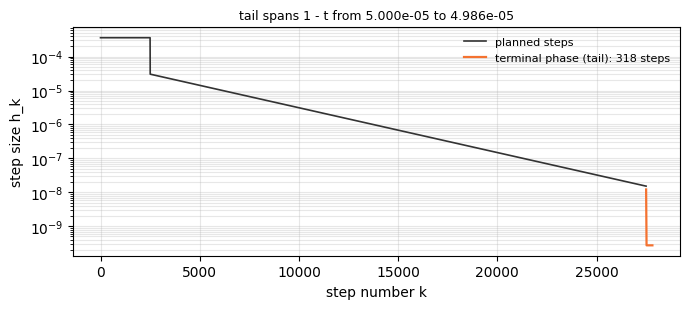

In [2]:
vt.fig_steps(d);

## 1b. Moment matching before and after the tail (seed 0)
For every imposed statistic φ_n: rel_n = (m̂_n − m_n) / |m_n|, with m_n its mean on the data and m̂_n its mean on the 5000 walkers, at the end of the planned grid (before the tail) and after the tail. Dashed line = 1 %. Statistics with a target close to 0 can show a large relative error for a small absolute one.

,n,> 1 % before,> 1 % after,> 0.1 % before,> 0.1 % after,max before,max after
family,,,,,,,
L_6,9,0,0,0,0,0.000014,0.000001
Scalar_psi,67,9,0,13,0,2.346417,0.000569
Scalar_morlet,55,3,0,6,0,0.075251,0.000225
Scat3 Real,44,2,0,6,0,0.052659,0.000053
Scat3 Imag_nolp,36,5,0,8,1,5.230900,0.002181
Scat4 Real_Q1_diag,120,3,0,11,0,0.022318,0.000015
Scat4 Imag_Q1,56,0,0,2,0,0.002814,0.000046


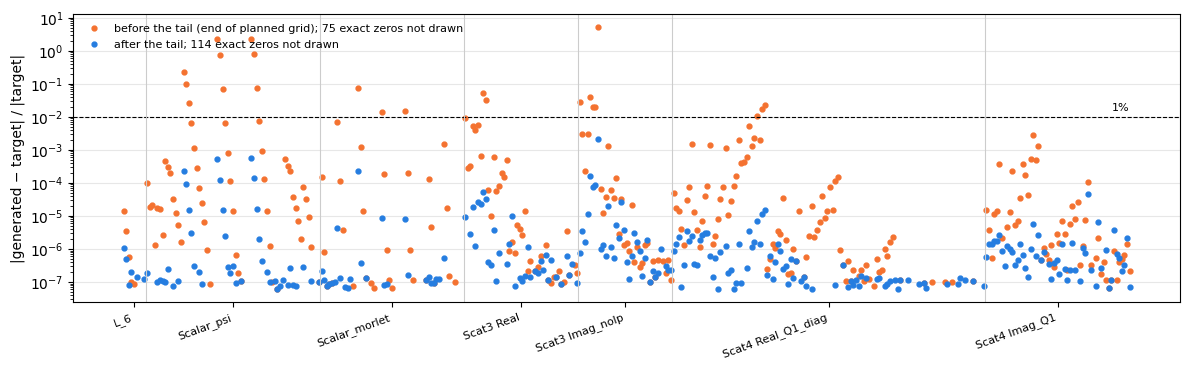

In [3]:
T = vt.load_before_after('errors_m1024_smoke/turbulencesynth_M1024_J8_Q3_sigma2.5_nt27500_n1_5000_lam0.0_thomas_nsub1_moment_f64_dedupfilt1e-08_seed_900_termsab244184_turbulence_nested_M3_bicw_allmass_scat34d_term_lagr1024J8_q3cut_n15000_20261124_2308_before_after.csv')
vt.fig_moments_before_after(T)
vt.moments_table(T)

## 2. A few coefficients along the run (seed 0)
One figure per coefficient (per family, the one that moves log p most). Left: the whole run against 1 − t on a log scale. Right: the last steps against the step number, so that each tail step is visible (the horizontal axis is then NOT proportional to time). Dashed line = end of the planned grid.

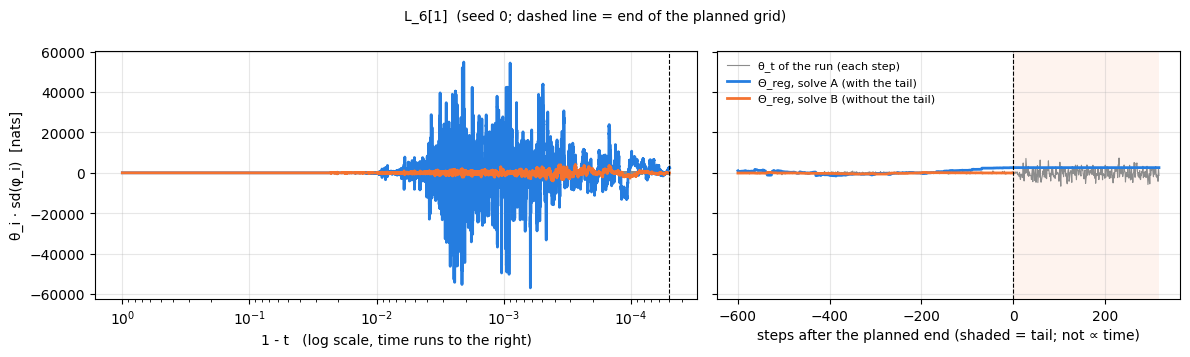

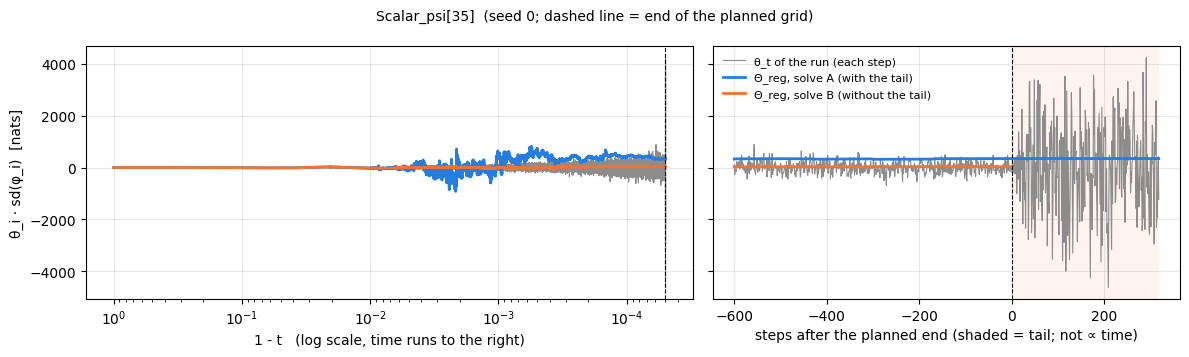

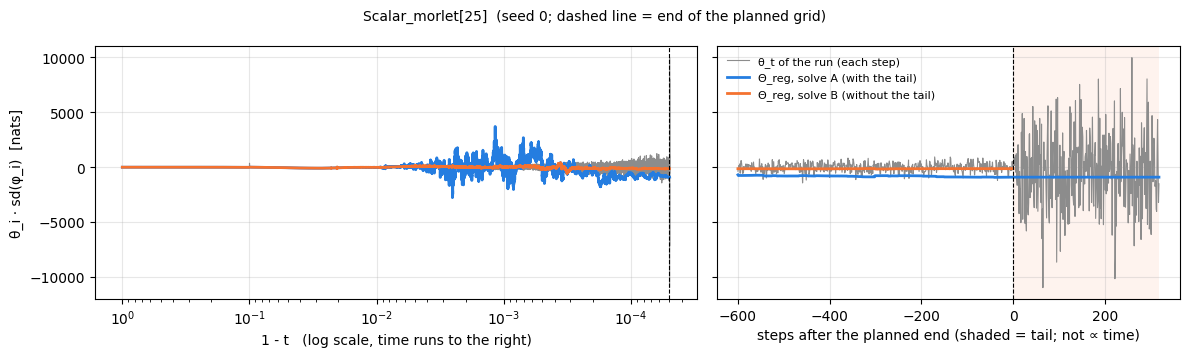

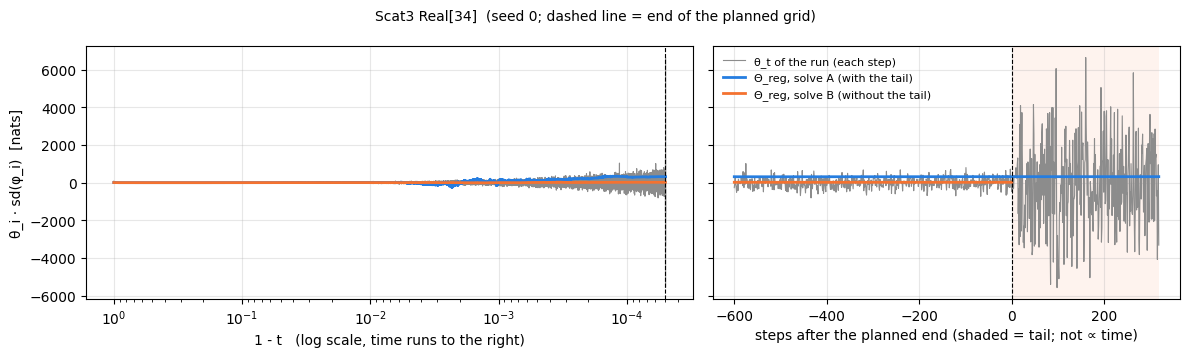

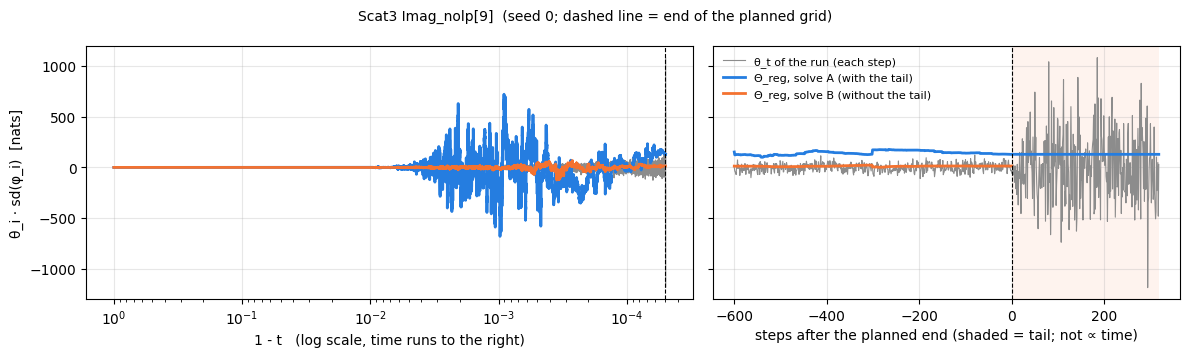

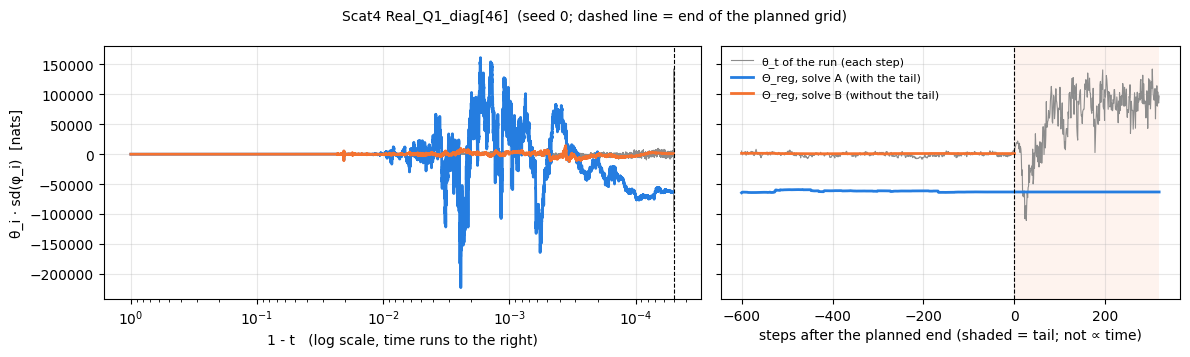

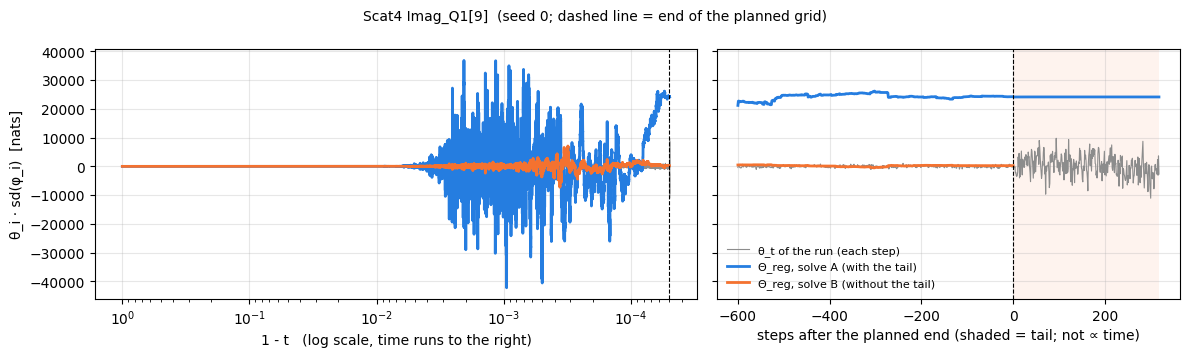

In [4]:
for j in range(len(d['sel'])):
    vt.fig_coefficient(d, j)

## 3. Final values across seeds
Same coefficients, value at the end, one dot per seed, for the three estimates: θ_t at the last step, Θ_reg(1) with the tail (A), without it (B). Agreement between the 3 seeds = the estimate reflects the model, not the noise of the run.

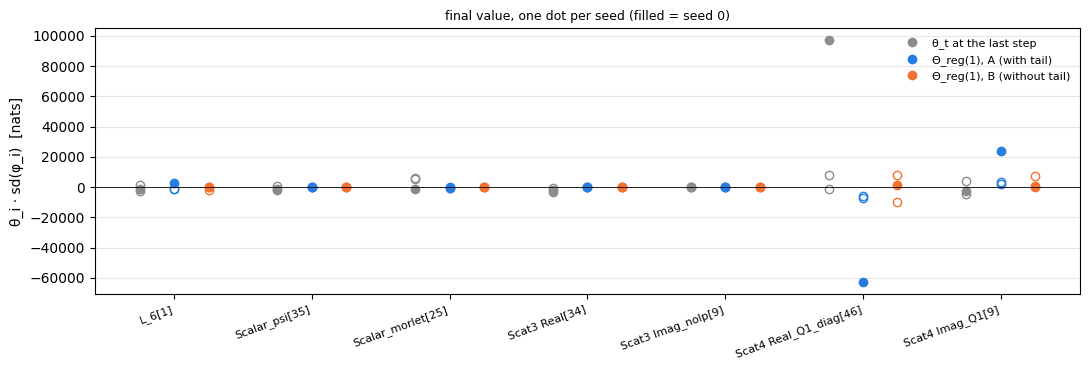

In [5]:
vt.fig_final_selected(d);

## 4. Spread across seeds, all coefficients
std over the 3 seeds of θ_i · sd(φ_i) at the end, for every coefficient i (387). Smaller = more reproducible. Table: median per family.

,θ_t at the last step,"Θ_reg(1), A (with tail)","Θ_reg(1), B (without tail)"
L_6,2379.556,209.205,33.175
Scalar_psi,61.295,4.961,2.820
Scalar_morlet,2393.059,25.199,3.221
Scat3 Real,209.241,20.549,7.370
Scat3 Imag_nolp,252.181,17.290,3.469
Scat4 Real_Q1_diag,5382.449,1580.971,774.566
Scat4 Imag_Q1,1666.145,553.051,214.208
all,1158.121,58.880,19.869


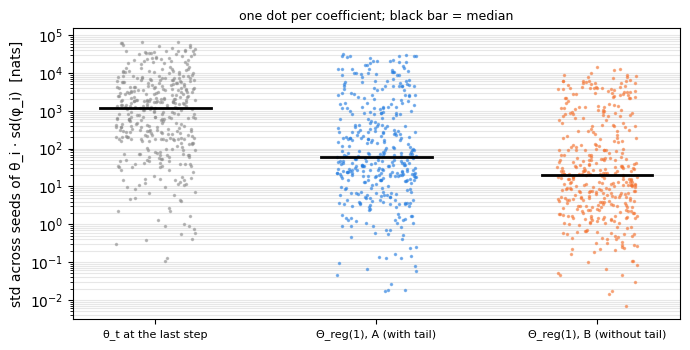

In [6]:
vt.fig_seed_spread(d)
vt.seed_spread_table(d).round(3)